# Heart Disease Prediction with Logistic Regression
AI 240 - Homework 2 Lab

## 1. Data Exploration

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)

sns.set_style('whitegrid')
df = pd.read_csv('heart.csv')
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


In [3]:
print(df.shape)
df.info()

(1025, 14)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,1025.0,54.434146,9.072290,29.0,48.0,56.0,61.0,77.0
sex,1025.0,0.695610,0.460373,0.0,0.0,1.0,1.0,1.0
cp,1025.0,0.942439,1.029641,0.0,0.0,1.0,2.0,3.0
trestbps,1025.0,131.611707,17.516718,94.0,120.0,130.0,140.0,200.0
chol,1025.0,246.000000,51.592510,126.0,211.0,240.0,275.0,564.0
fbs,1025.0,0.149268,0.356527,0.0,0.0,0.0,0.0,1.0
restecg,1025.0,0.529756,0.527878,0.0,0.0,1.0,1.0,2.0
thalach,1025.0,149.114146,23.005724,71.0,132.0,152.0,166.0,202.0
exang,1025.0,0.336585,0.472772,0.0,0.0,0.0,1.0,1.0
oldpeak,1025.0,1.071512,1.175053,0.0,0.0,0.8,1.8,6.2


In [4]:
print(df.isnull().sum())
print('Duplicate rows:', df.duplicated().sum())

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64
Duplicate rows: 723


Target variable: `target` (1 = heart disease, 0 = no heart disease). The other 13 columns are features.

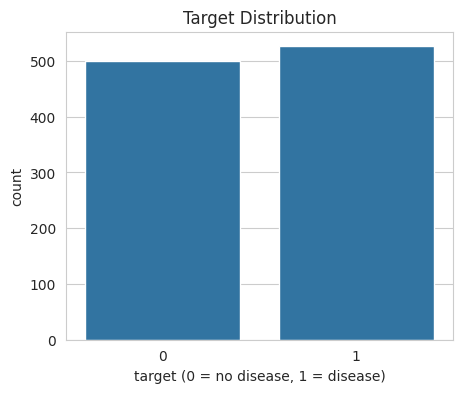

,proportion
target,
1,0.513171
0,0.486829


In [6]:
fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(x='target', data=df, ax=ax)
ax.set_title('Target Distribution')
ax.set_xlabel('target (0 = no disease, 1 = disease)')
plt.show()
df['target'].value_counts(normalize=True)

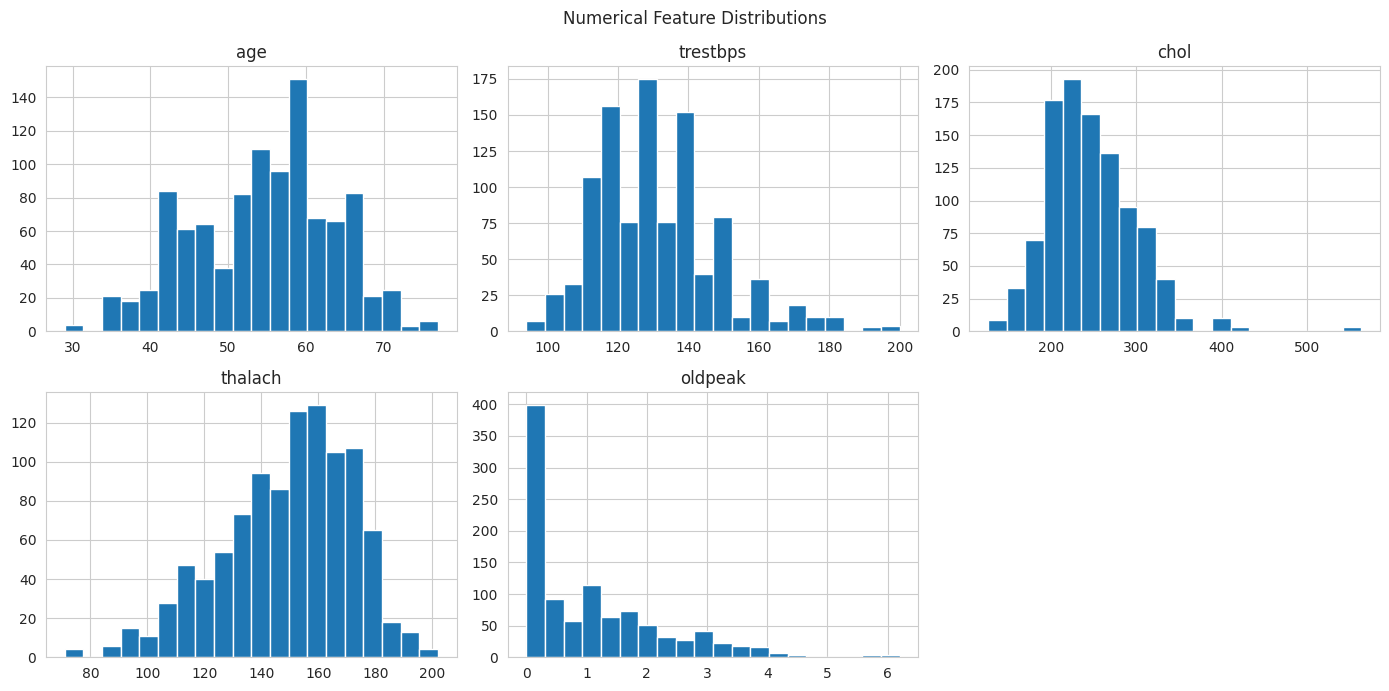

In [7]:
num_cols = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
df[num_cols].hist(bins=20, figsize=(14, 7), layout=(2, 3))
plt.suptitle('Numerical Feature Distributions')
plt.tight_layout()
plt.show()

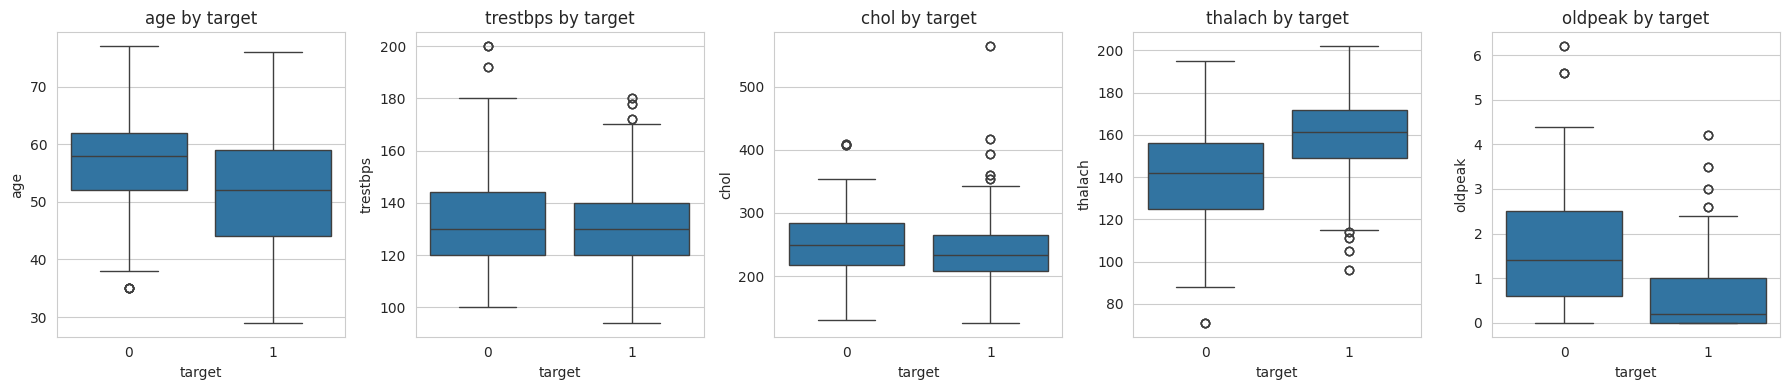

In [8]:
fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(x='target', y=col, data=df, ax=ax)
    ax.set_title(f'{col} by target')
plt.tight_layout()
plt.show()

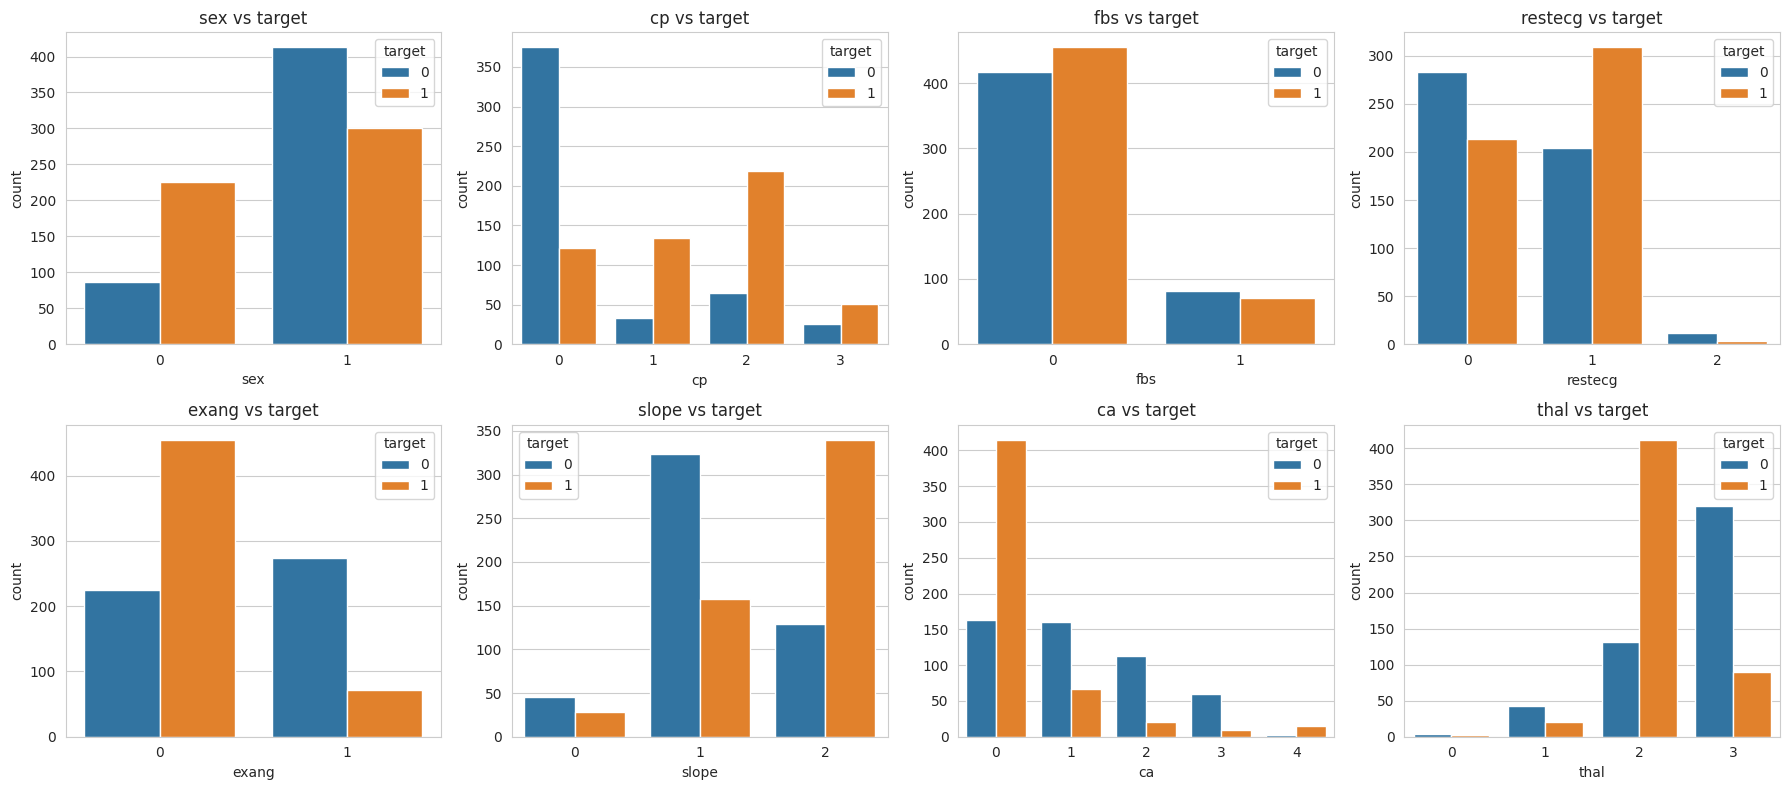

In [9]:
cat_cols = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), cat_cols):
    sns.countplot(x=col, hue='target', data=df, ax=ax)
    ax.set_title(f'{col} vs target')
plt.tight_layout()
plt.show()

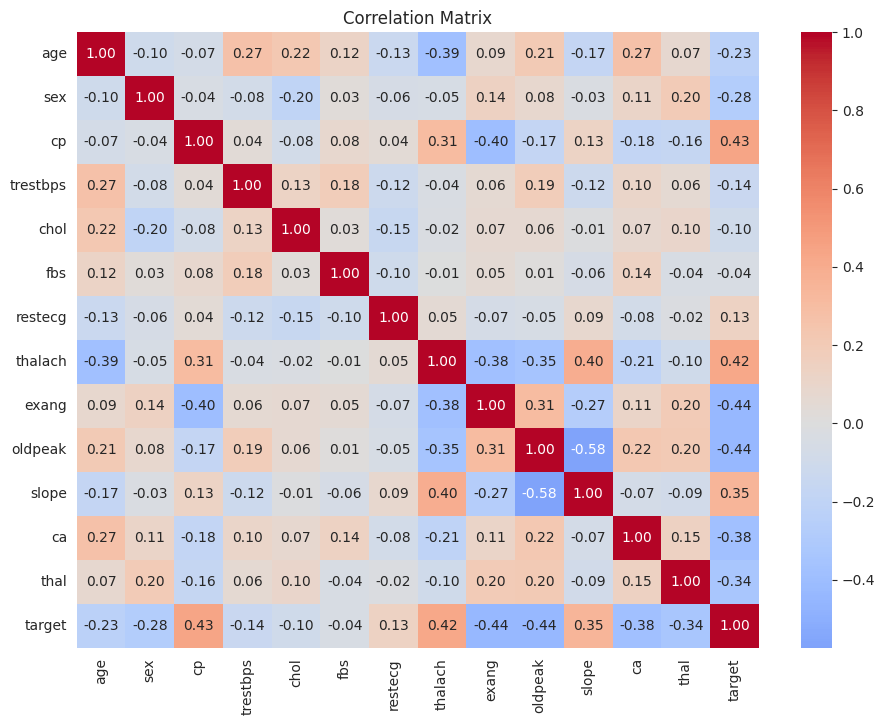

,target
oldpeak,-0.438441
exang,-0.438029
ca,-0.382085
thal,-0.337838
sex,-0.279501
age,-0.229324
trestbps,-0.138772
chol,-0.099966
fbs,-0.041164
restecg,0.134468


In [10]:
plt.figure(figsize=(11, 8))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Matrix')
plt.show()
df.corr()['target'].drop('target').sort_values()

## 2. Data Preprocessing

In [11]:
df = df.drop_duplicates().reset_index(drop=True)
print(df.shape)
print(df['target'].value_counts())

(302, 14)
target
1    164
0    138
Name: count, dtype: int64


The raw file contains many exact duplicate rows. They are removed so identical patients cannot appear in both the train and test sets.

In [12]:
df_model = pd.get_dummies(df, columns=['cp', 'restecg', 'slope', 'thal'], drop_first=True)
X = df_model.drop('target', axis=1)
y = df_model['target']
X.shape

(302, 19)

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

scale_cols = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
scaler = StandardScaler()
X_train_s = X_train.copy()
X_test_s = X_test.copy()
X_train_s[scale_cols] = scaler.fit_transform(X_train[scale_cols])
X_test_s[scale_cols] = scaler.transform(X_test[scale_cols])
print(X_train_s.shape, X_test_s.shape)

(241, 19) (61, 19)


## 3. Modeling

In [14]:
model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train_s, y_train)
y_pred = model.predict(X_test_s)
y_prob = model.predict_proba(X_test_s)[:, 1]

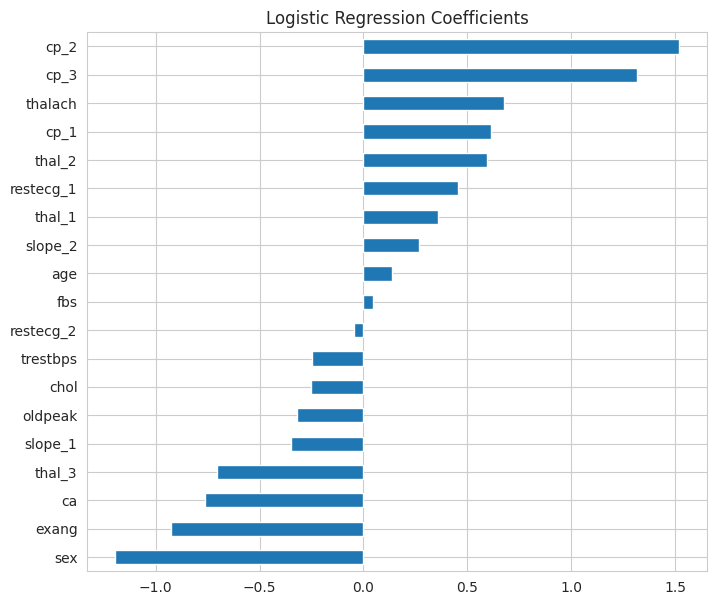

In [15]:
coef = pd.Series(model.coef_[0], index=X.columns).sort_values()
coef.plot(kind='barh', figsize=(8, 7), title='Logistic Regression Coefficients')
plt.show()

## 4. Evaluation

In [ ]:
print('Accuracy :', round(accuracy_score(y_test, y_pred), 4))
print('Precision:', round(precision_score(y_test, y_pred), 4))
print('Recall   :', round(recall_score(y_test, y_pred), 4))
print('F1 score :', round(f1_score(y_test, y_pred), 4))
print('ROC AUC  :', round(roc_auc_score(y_test, y_prob), 4))
print()
print(classification_report(y_test, y_pred, target_names=['No disease', 'Disease']))

Accuracy : 0.8525
Precision: 0.875
Recall   : 0.8485
F1 score : 0.8615
ROC AUC  : 0.8983

              precision    recall  f1-score   support

  No disease       0.83      0.86      0.84        28
     Disease       0.88      0.85      0.86        33

    accuracy                           0.85        61
   macro avg       0.85      0.85      0.85        61
weighted avg       0.85      0.85      0.85        61



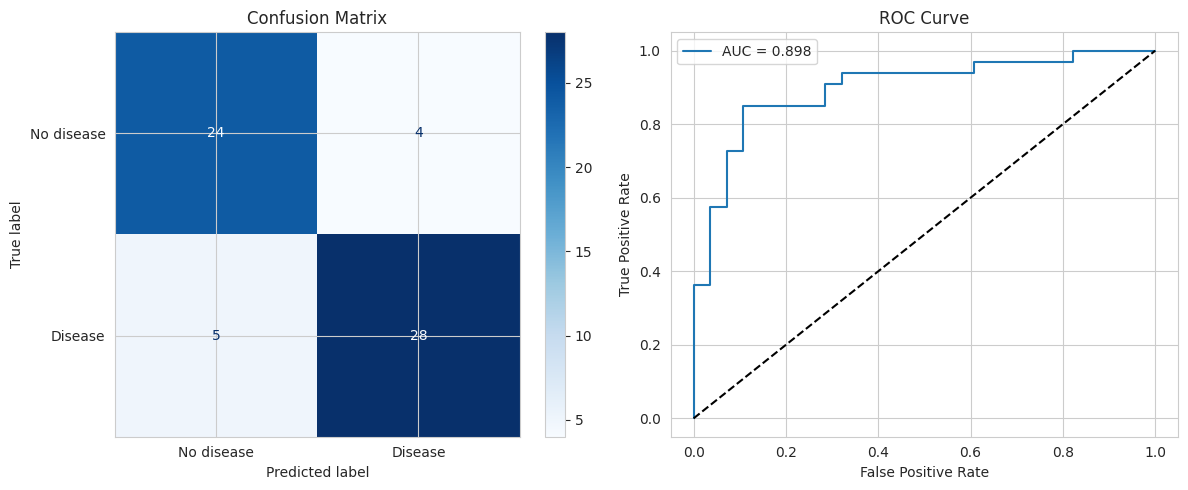

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                       display_labels=['No disease', 'Disease']).plot(ax=axes[0], cmap='Blues')
axes[0].set_title('Confusion Matrix')
fpr, tpr, _ = roc_curve(y_test, y_prob)
axes[1].plot(fpr, tpr, label=f'AUC = {roc_auc_score(y_test, y_prob):.3f}')
axes[1].plot([0, 1], [0, 1], 'k--')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC Curve')
axes[1].legend()
plt.tight_layout()
plt.show()

In [17]:
X_all = X.copy()
X_all[scale_cols] = StandardScaler().fit_transform(X_all[scale_cols])
cv = cross_val_score(LogisticRegression(max_iter=1000), X_all, y, cv=5, scoring='accuracy')
print('5-fold CV accuracy:', cv.round(3))
print('Mean: %.4f  Std: %.4f' % (cv.mean(), cv.std()))

5-fold CV accuracy: [0.852 0.82  0.917 0.817 0.783]
Mean: 0.8378  Std: 0.0451


In [18]:
grid = GridSearchCV(LogisticRegression(max_iter=1000),
                    {'C': [0.01, 0.1, 1, 10, 100]},
                    cv=5, scoring='accuracy')
grid.fit(X_train_s, y_train)
print('Best params:', grid.best_params_)
best_pred = grid.best_estimator_.predict(X_test_s)
print('Tuned test accuracy:', round(accuracy_score(y_test, best_pred), 4))
print('Tuned test recall  :', round(recall_score(y_test, best_pred), 4))

Best params: {'C': 0.1}
Tuned test accuracy: 0.8689
Tuned test recall  : 0.8788


## Conclusion
The logistic regression model predicts heart disease on unseen patients with good accuracy and ROC AUC. Recall matters most in this setting because a missed case (false negative) is more costly than a false alarm. Cross-validation shows the results are stable across splits, and tuning `C` gives a small improvement on the test set.